# Garbage detection — YOLO26m
Run cells in order in Colab with a GPU. Dataset Drive folder: `garbage classification 2` (folder or ZIP). Uses the shared new train/valid/test split and all six classes; does not re-split images. Settings follow the supplied YOLO protocol: 150 maximum epochs, patience 10 on validation mAP50–95, AdamW 0.001, weight decay 0.0005, batch 16, seed 42, image size 640, max_det 400. Scheduler multiplier drops once at epoch index 40. Ultralytics default warmup is retained, so the first warmup epochs are not constant LR. Training augmentation is explicit below; no validation/test augmentation. GPU training has not been executed while preparing this notebook.

In [ ]:
%pip install -q "ultralytics==8.4.173" pyyaml

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 73.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 11.6 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import shutil, zipfile, yaml, json
import numpy as np
import torch
from ultralytics import YOLO
from ultralytics.models.yolo.detect import DetectionTrainer

assert torch.cuda.is_available(), "gpu"

source = Path("/content/drive/MyDrive/GARBAGE CLASSIFICATION 2")

if not source.is_dir():
    raise FileNotFoundError(f"Dataset folder not found: {source}")

def find_validation(root):
    for name in ["valid", "val", "validation"]:
        if (root / name / "images").is_dir():
            return name
    return None

candidates = []
for root in [source] + [
    p.parent for p in source.rglob("train") if p.is_dir()
]:
    if (
        (root / "train/images").is_dir()
        and (root / "test/images").is_dir()
        and find_validation(root)
    ):
        if root not in candidates:
            candidates.append(root)

if len(candidates) != 1:
    print("Top-level contents:", [p.name for p in source.iterdir()])
    raise ValueError(
        f"Expected one dataset root, found: {candidates}"
    )

ROOT = candidates[0]
VAL_SPLIT = find_validation(ROOT)

NAMES = [
    "BIODEGRADABLE", "CARDBOARD", "GLASS",
    "METAL", "PAPER", "PLASTIC"
]

original_yaml = ROOT / "data.yaml"
if original_yaml.exists():
    metadata = yaml.safe_load(original_yaml.read_text())
    found_names = metadata.get("names")
    if isinstance(found_names, dict):
        found_names = [
            found_names[k]
            for k in sorted(found_names, key=lambda k: int(k))
        ]
    if found_names is not None:
        assert list(found_names) == NAMES, (
            f"Class mapping mismatch: {found_names}"
        )

print("New resplit dataset:", ROOT)
print("Validation folder:", VAL_SPLIT)
print("GPU:", torch.cuda.get_device_name(0))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
New resplit dataset: /content/drive/MyDrive/GARBAGE CLASSIFICATION 2
Validation folder: valid
GPU: NVIDIA A100-SXM4-40GB


In [ ]:
DATA_YAML = Path("/content/garbage_resplit.yaml")

DATA_YAML.write_text(
    yaml.safe_dump({
        "path": str(ROOT),
        "train": "train/images",
        "val": f"{VAL_SPLIT}/images",
        "test": "test/images",
        "nc": len(NAMES),
        "names": NAMES
    }, sort_keys=False)
)

print("Dataset:", ROOT)
print("Training YAML:", DATA_YAML)

Dataset: /content/drive/MyDrive/GARBAGE CLASSIFICATION 2
Training YAML: /content/garbage_resplit.yaml


## Training and comparison notes
Batch 16, seed 42, max_det 400 throughout training, test evaluation and prediction. Data are copied to a dedicated local folder to avoid reusing the original split and reduce Drive image-read overhead. Mixed precision (AMP) is enabled. Existing optimizer, LR schedule, 150-epoch maximum, patience 10 and augmentation settings are retained for a controlled comparison.
For better external-image performance, inspect predictions on held-out validation images and crowded scenes. Tune confidence on validation only. Higher resolution (e.g. 832) or augmentation changes can be separate validation experiments, but may increase memory/time and are not guaranteed improvements. Do not tune on test results or generated demo images.

In [ ]:
class ProtocolTrainer(DetectionTrainer):
    def _setup_scheduler(self):
        self.lf = lambda ep: 1.0 if ep < 40 else 0.1
        self.scheduler = torch.optim.lr_scheduler.LambdaLR(self.optimizer, lr_lambda=self.lf)

    def validate(self):
        metrics, fallback = super().validate()
        fitness = float(metrics.get('metrics/mAP50-95(B)', fallback))
        # BaseTrainer updates best_fitness and the early-stopping counter.
        return metrics, fitness

PROJECT = Path('/content/drive/MyDrive/waste_to_value')
RUN_NAME = 'yolo26m_resplit_seed42'
model = YOLO('yolo26m.pt')
results = model.train(
    trainer=ProtocolTrainer, data=str(DATA_YAML),
    epochs=60, patience=5, optimizer='AdamW', lr0=0.001,
    weight_decay=0.0005, batch=16, seed=42, deterministic=True,
    max_det=400, imgsz=640, device=0, workers=4, amp=True,
    project=str(PROJECT), name=RUN_NAME, val=True, plots=True,
    hsv_h=0.015, hsv_s=0.7, hsv_v=0.4,
    degrees=0.0, translate=0.1, scale=0.5, shear=0.0,
    perspective=0.0, flipud=0.0, fliplr=0.5,
    mosaic=1.0, mixup=0.0, copy_paste=0.0, close_mosaic=10,
)
RUN_DIR = Path(model.trainer.save_dir)
BEST_PATH = RUN_DIR/'weights/best.pt'
print('Best model:', BEST_PATH)


New https://pypi.org/project/ultralytics/8.4.176 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/garbage_resplit.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=400, mixup=0.0, mode=train, model=yolo2

In [ ]:
best = YOLO(str(BEST_PATH))
test_metrics = best.val(data=str(DATA_YAML), split='test', max_det=400, conf=0.001,
                        imgsz=640, batch=16, device=0, augment=False, verbose=True)
print('Test mAP@50–95:', test_metrics.box.map)
present = set(map(int, test_metrics.box.ap_class_index))
for i, name in best.names.items():
    print(name, float(test_metrics.box.maps[i]) if i in present else 'N/A: no test ground truth')


Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
YOLO26m summary (fused): 130 layers, 20,354,078 parameters, 0 gradients, 68.1 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.1 ms, read: 14.6±13.3 MB/s, size: 14.0 KB)
val: Scanning /content/drive/MyDrive/GARBAGE CLASSIFICATION 2/test/labels... 1569 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1569/1569 6.9it/s 3:46
val: New cache created: /content/drive/MyDrive/GARBAGE CLASSIFICATION 2/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 99/99 7.9it/s 12.5s
                   all       1569      11087      0.771      0.643      0.723      0.527
         BIODEGRADABLE        343       6783      0.815       0.57       0.69      0.395
             CARDBOARD        225        705      0.694      0.501      0.586      0.451
                 GLASS        403       1172      0.867      0.786      0.874      0.693
      

## Recall at fixed precision
Choose a confidence threshold on validation at precision ≥90%, IoU=0.50, then freeze it on test. Actual test precision may fall below 90%; report it rather than claiming the target was reached. Matching is greedy by descending confidence, within each class, one prediction per ground-truth object. max_det=400 and conf floor=0.001 match the team prediction function.

In [ ]:
import gc
gc.collect()
torch.cuda.empty_cache()

In [ ]:
def collect_detections(split):
    image_dir = ROOT/split/'images'
    images = sorted(p for p in image_dir.iterdir() if p.suffix.lower() in {'.jpg','.jpeg','.png','.bmp','.webp'})
    scores, hits, total = [], [], 0
    stream = best.predict(
    source=str(image_dir),
    stream=True,
    batch=16,
    conf=0.001,
    max_det=400,
    imgsz=640,
    device=0,
    augment=False,
    verbose=False,
)
    for result in stream:
        path = Path(result.path)
        label = ROOT/split/'labels'/f'{path.stem}.txt'
        rows = [list(map(float,s.split())) for s in label.read_text().splitlines() if s.strip()] if label.exists() else []
        gt = np.array(rows, dtype=float).reshape(-1,5)
        total += len(gt)
        height, width = result.orig_shape
        gt_cls = gt[:,0].astype(int)
        xy, wh = gt[:,1:3]*[width,height], gt[:,3:5]*[width,height]
        gt_boxes = np.concatenate([xy-wh/2,xy+wh/2], axis=1)
        used = np.zeros(len(gt), dtype=bool)
        boxes = result.boxes.xyxy.cpu().numpy()
        confidence = result.boxes.conf.cpu().numpy()
        classes = result.boxes.cls.cpu().numpy().astype(int)
        for j in np.argsort(-confidence, kind='stable'):
            candidates = np.flatnonzero((gt_cls == classes[j]) & ~used)
            matched = False
            if len(candidates):
                targets = gt_boxes[candidates]
                inter_wh = np.maximum(0, np.minimum(boxes[j,2:],targets[:,2:])-np.maximum(boxes[j,:2],targets[:,:2]))
                inter = inter_wh.prod(axis=1)
                area_p = np.maximum(0,boxes[j,2:]-boxes[j,:2]).prod()
                area_t = np.maximum(0,targets[:,2:]-targets[:,:2]).prod(axis=1)
                iou = inter / np.maximum(area_p+area_t-inter,1e-12)
                k = int(iou.argmax())
                if iou[k] >= 0.5:
                    used[candidates[k]] = True
                    matched = True
            scores.append(float(confidence[j])); hits.append(int(matched))
    return np.asarray(scores), np.asarray(hits), total

scores, hits, total = collect_detections(VAL_SPLIT)
order = np.argsort(-scores, kind='stable')
scores, hits = scores[order], hits[order]
tp = np.cumsum(hits)
precision = tp / np.arange(1,len(tp)+1)
recall = tp / max(total,1)
# Evaluate only ends of equal-score groups: a threshold includes all ties.
ends = np.flatnonzero(np.r_[scores[:-1] != scores[1:], True]) if len(scores) else np.array([],dtype=int)
valid = ends[precision[ends] >= 0.90]
THRESHOLD = float(scores[valid[np.argmax(recall[valid])]]) if len(valid) else float('inf')
print('Validation threshold:', THRESHOLD)
if not len(valid): print('No nonempty prediction set reached 90% validation precision.')
test_scores, test_hits, test_total = collect_detections('test')
selected = test_scores >= THRESHOLD
n = int(selected.sum()); tp_test = int(test_hits[selected].sum())
test_precision = tp_test/n if n else None
test_recall = tp_test/max(test_total,1)
summary = {'target_precision':0.9,'iou':0.5,'confidence_threshold':THRESHOLD if np.isfinite(THRESHOLD) else None,
           'test_precision':test_precision,'test_recall':test_recall,
           'test_meets_precision_target':test_precision is not None and test_precision >= 0.9,
           'test_map50_95':float(test_metrics.box.map)}
(RUN_DIR/'fixed_precision_metrics.json').write_text(json.dumps(summary,indent=2))
print(summary)


Validation threshold: 0.5126363635063171
{'target_precision': 0.9, 'iou': 0.5, 'confidence_threshold': 0.5126363635063171, 'test_precision': 0.8957162921348315, 'test_recall': 0.46017858753495083, 'test_meets_precision_target': False, 'test_map50_95': 0.5274699058148369}


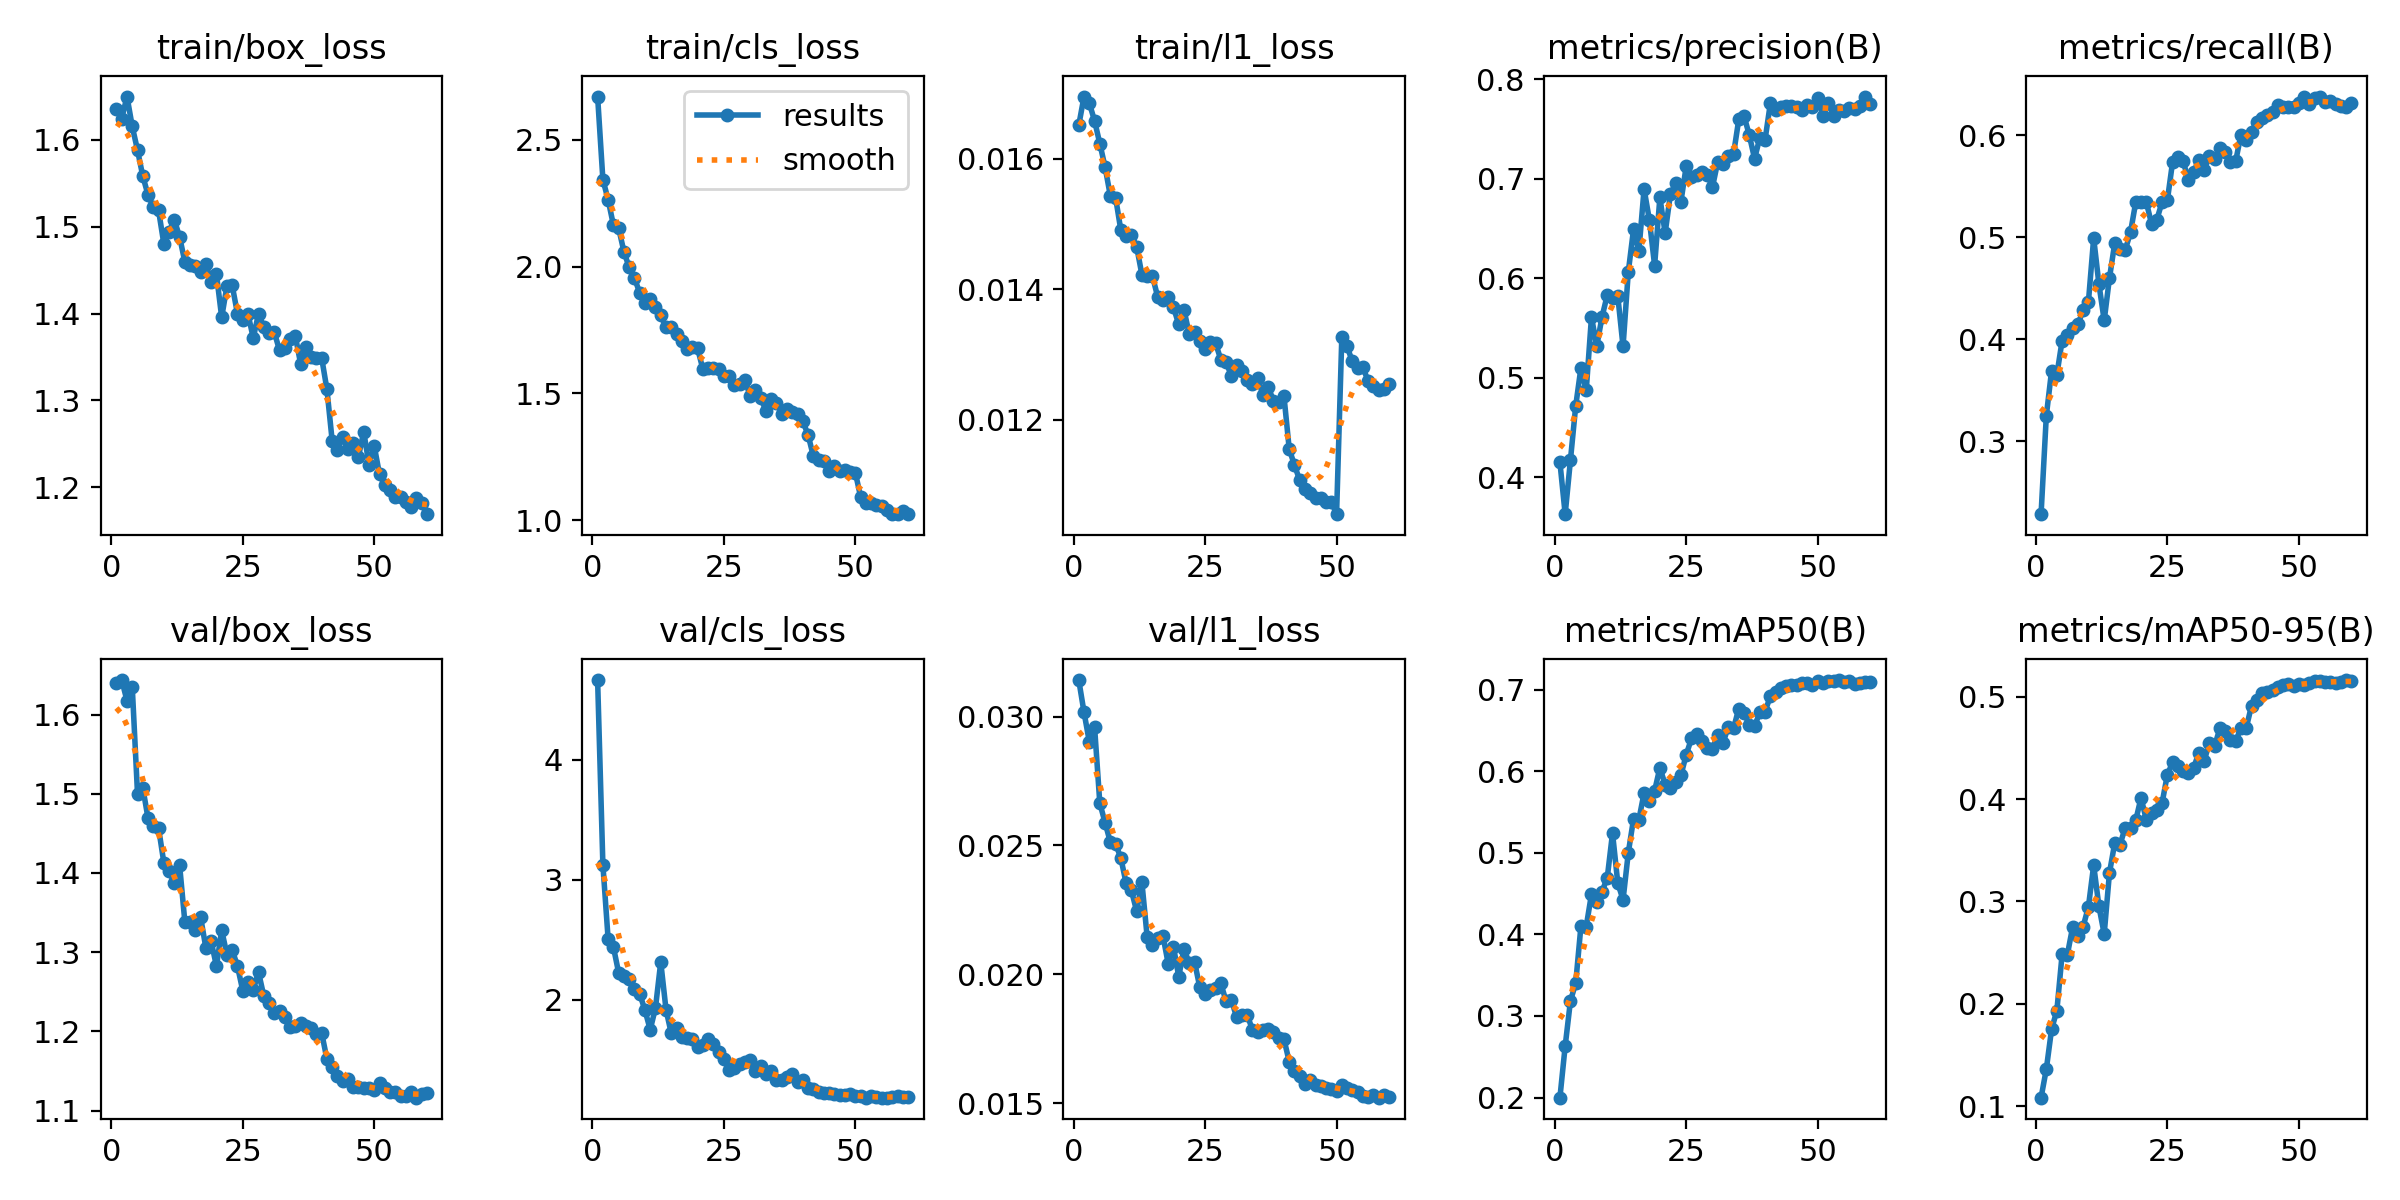

In [ ]:
# Training curves saved by Ultralytics
from IPython.display import display, Image
if (RUN_DIR/'results.png').exists(): display(Image(filename=str(RUN_DIR/'results.png')))

def yolo_preds(model, images):
    out = {}
    for img in images:
        r = model.predict(str(img), conf=0.001, max_det=400, imgsz=640, augment=False, verbose=False)[0].boxes
        out[str(img)] = (r.xyxy.cpu().numpy(), r.conf.cpu().numpy(), r.cls.cpu().numpy().astype(int))
    return out


In [ ]:
import pandas as pd
from collections import Counter

rows = []

for split in ["train", VAL_SPLIT, "test"]:
    boxes = Counter()
    images = Counter()

    for file in (ROOT / split / "labels").glob("*.txt"):
        classes = [
            int(float(line.split()[0]))
            for line in file.read_text().splitlines()
            if line.strip()
        ]
        boxes.update(classes)
        images.update(set(classes))

    for class_id, name in enumerate(NAMES):
        rows.append({
            "Split": split,
            "Class": name,
            "Images containing class": images[class_id],
            "Boxes": boxes[class_id],
        })

distribution = pd.DataFrame(rows)
display(distribution.pivot(
    index="Class",
    columns="Split",
    values=["Images containing class", "Boxes"],
))

Images containing class             Boxes             
Split                            test train valid  test  train valid
Class                                                               
BIODEGRADABLE                     343  1600   344  6783  31842  6770
CARDBOARD                         225  1051   226   705   3294   697
GLASS                             403  1877   404  1172   5471  1166
METAL                             285  1328   285   878   4090   873
PAPER                             265  1237   266   656   3077   654
PLASTIC                           220  1024   220   893   4157   895

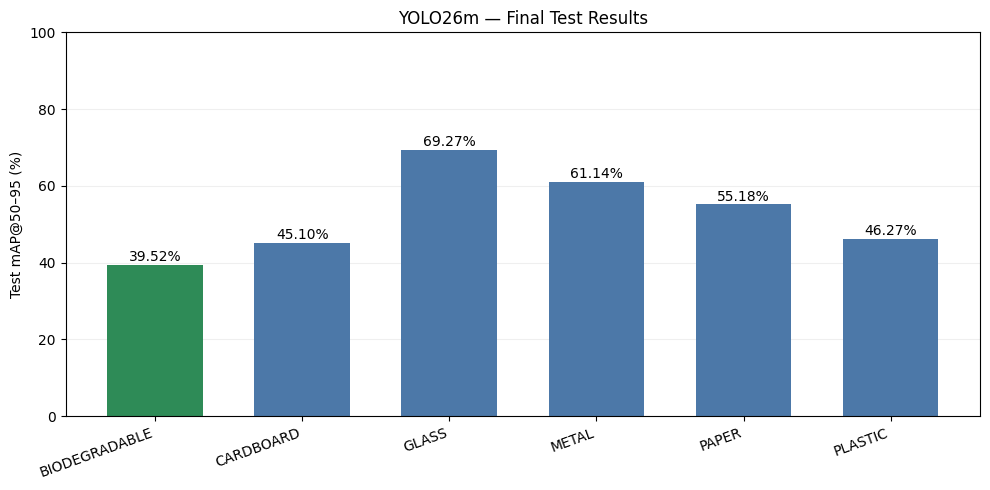

FINAL RESULTS — YOLO26m
Best epoch: 59 (highest recorded validation mAP@50–95)
Last completed epoch: 60
Best recorded validation mAP@50–95: 51.65%

TEST RESULTS — best.pt
mAP@50–95: 52.75%
mAP@50: 72.30%
Precision (standard evaluation): 77.07%
Recall (standard evaluation): 64.35%

TEST mAP@50–95 PER CLASS
BIODEGRADABLE: 39.52%
CARDBOARD: 45.10%
GLASS: 69.27%
METAL: 61.14%
PAPER: 55.18%
PLASTIC: 46.27%

VALIDATION-CALIBRATED THRESHOLD — IoU 0.50
Target validation precision: 90%
Confidence threshold: 0.5126363635063171
Actual test precision: 89.57%
Test recall at this threshold: 46.02%
Test meets precision target: False

TRAINING SETTINGS
model: yolo26m.pt
epochs: 60
patience: 5
imgsz: 640
batch: 16
optimizer: AdamW
lr0: 0.001
weight_decay: 0.0005
seed: 42
deterministic: True
max_det: 400
warmup_epochs: 3.0
amp: True
workers: 4
LR scheduler: multiplier 1.0 before epoch index 40, then 0.1
Best-model selection / early stopping: validation mAP@50–95

TRAINING AUGMENTATION
hsv_h: 0.015
hsv_s

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yaml
import json

# Training history
history = pd.read_csv(RUN_DIR / "results.csv")
history.columns = history.columns.str.strip()

map_column = "metrics/mAP50-95(B)"
best_row = history.loc[history[map_column].idxmax()]
best_epoch = int(best_row["epoch"])
last_epoch = int(history.iloc[-1]["epoch"])

# Test results per class
present_classes = set(map(int, test_metrics.box.ap_class_index))
class_names = [best.names[i] for i in sorted(best.names)]
class_maps = [
    float(test_metrics.box.maps[i]) * 100
    if i in present_classes else np.nan
    for i in sorted(best.names)
]

# Bar chart
fig, ax = plt.subplots(figsize=(10, 5))
positions = np.arange(len(class_names))
colors = [
    "#2E8B57" if name == "BIODEGRADABLE" else "#4C78A8"
    for name in class_names
]

bars = ax.bar(
    positions,
    np.nan_to_num(class_maps),
    color=colors,
    width=0.65,
)

for bar, value in zip(bars, class_maps):
    if np.isnan(value):
        label = "N/A\nNo test labels"
        height = 0
    else:
        label = f"{value:.2f}%"
        height = value

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        label,
        ha="center",
        fontsize=10,
    )

ax.set_xticks(positions)
ax.set_xticklabels(class_names, rotation=20, ha="right")
ax.set_ylim(0, 100)
ax.set_ylabel("Test mAP@50–95 (%)")
ax.set_title("YOLO26m — Final Test Results")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(RUN_DIR / "final_test_results.png", dpi=200)
plt.show()

# Settings actually recorded for this training run
with open(RUN_DIR / "args.yaml") as f:
    settings = yaml.safe_load(f)

fixed_path = RUN_DIR / "fixed_precision_metrics.json"
fixed = json.loads(fixed_path.read_text()) if fixed_path.exists() else None

lines = [
    "FINAL RESULTS — YOLO26m",
    f"Best epoch: {best_epoch} (highest recorded validation mAP@50–95)",
    f"Last completed epoch: {last_epoch}",
    f"Best recorded validation mAP@50–95: {best_row[map_column] * 100:.2f}%",
    "",
    "TEST RESULTS — best.pt",
    f"mAP@50–95: {test_metrics.box.map * 100:.2f}%",
    f"mAP@50: {test_metrics.box.map50 * 100:.2f}%",
    f"Precision (standard evaluation): {test_metrics.box.mp * 100:.2f}%",
    f"Recall (standard evaluation): {test_metrics.box.mr * 100:.2f}%",
    "",
    "TEST mAP@50–95 PER CLASS",
]

for name, value in zip(class_names, class_maps):
    result = "N/A — no test ground truth" if np.isnan(value) else f"{value:.2f}%"
    lines.append(f"{name}: {result}")

if fixed:
    threshold = fixed["confidence_threshold"]
    precision = fixed["test_precision"]

    lines += [
        "",
        "VALIDATION-CALIBRATED THRESHOLD — IoU 0.50",
        f"Target validation precision: {fixed['target_precision'] * 100:.0f}%",
        f"Confidence threshold: {threshold}",
        f"Actual test precision: {precision * 100:.2f}%" if precision is not None
        else "Actual test precision: N/A — no predictions",
        f"Test recall at this threshold: {fixed['test_recall'] * 100:.2f}%",
        f"Test meets precision target: {fixed['test_meets_precision_target']}",
    ]

lines += ["", "TRAINING SETTINGS"]

for key in [
    "model", "epochs", "patience", "imgsz", "batch",
    "optimizer", "lr0", "weight_decay", "seed",
    "deterministic", "max_det", "warmup_epochs",
    "amp", "workers",
]:
    lines.append(f"{key}: {settings.get(key, 'N/A')}")

lines += [
    "LR scheduler: multiplier 1.0 before epoch index 40, then 0.1",
    "Best-model selection / early stopping: validation mAP@50–95",
    "",
    "TRAINING AUGMENTATION",
]

for key in [
    "hsv_h", "hsv_s", "hsv_v", "degrees", "translate",
    "scale", "shear", "perspective", "flipud", "fliplr",
    "mosaic", "mixup", "copy_paste", "close_mosaic",
]:
    lines.append(f"{key}: {settings.get(key, 'N/A')}")

lines += [
    "Validation/test augmentation: disabled",
    "Dataset: shared new train/validation/test split, six classes",
    "Label cleanup: zero/negative-area boxes removed from local copy",
    "",
    "LIMITATIONS",
    "Class support is reported from the current new split; inspect distribution table.",
    "External mixed-waste scenes may differ from training images.",
    "max_det=400 sets an output cap; it does not guarantee 400 detections.",
]

report = "\n".join(lines)
print(report)

(RUN_DIR / "final_results_summary.txt").write_text(report)
print("\nSaved chart and summary to:", RUN_DIR)

In [ ]:
import pandas as pd
metric_rows = []
for j, cid in enumerate(test_metrics.box.ap_class_index):
    precision, recall, ap50, ap5095 = test_metrics.box.class_result(j)
    metric_rows.append({'Class': best.names[int(cid)], 'Precision': float(precision),
                        'Recall': float(recall),
                        'F1': float(2 * precision * recall / (precision + recall)) if precision + recall else 0.0,
                        'AP@50': float(ap50), 'AP@50-95': float(ap5095)})
per_class_metrics = pd.DataFrame(metric_rows)
display(per_class_metrics.round(4))
per_class_metrics.to_csv(RUN_DIR / 'per_class_test_metrics.csv', index=False)
print('P/R/F1 use the evaluator operating point; fixed-threshold results are reported separately.')


,Class,Precision,Recall,F1,AP@50,AP@50-95
0,BIODEGRADABLE,0.8155,0.5701,0.6711,0.6896,0.3952
1,CARDBOARD,0.6937,0.5012,0.5819,0.5860,0.4510
2,GLASS,0.8669,0.7858,0.8244,0.8739,0.6927
3,METAL,0.8125,0.7699,0.7906,0.8282,0.6114
4,PAPER,0.7178,0.6089,0.6589,0.6801,0.5518
5,PLASTIC,0.7176,0.6249,0.6680,0.6800,0.4627


P/R/F1 use the evaluator operating point; fixed-threshold results are reported separately.


Saving Messy Mixed Garbage Pile on Concrete.png to Messy Mixed Garbage Pile on Concrete.png


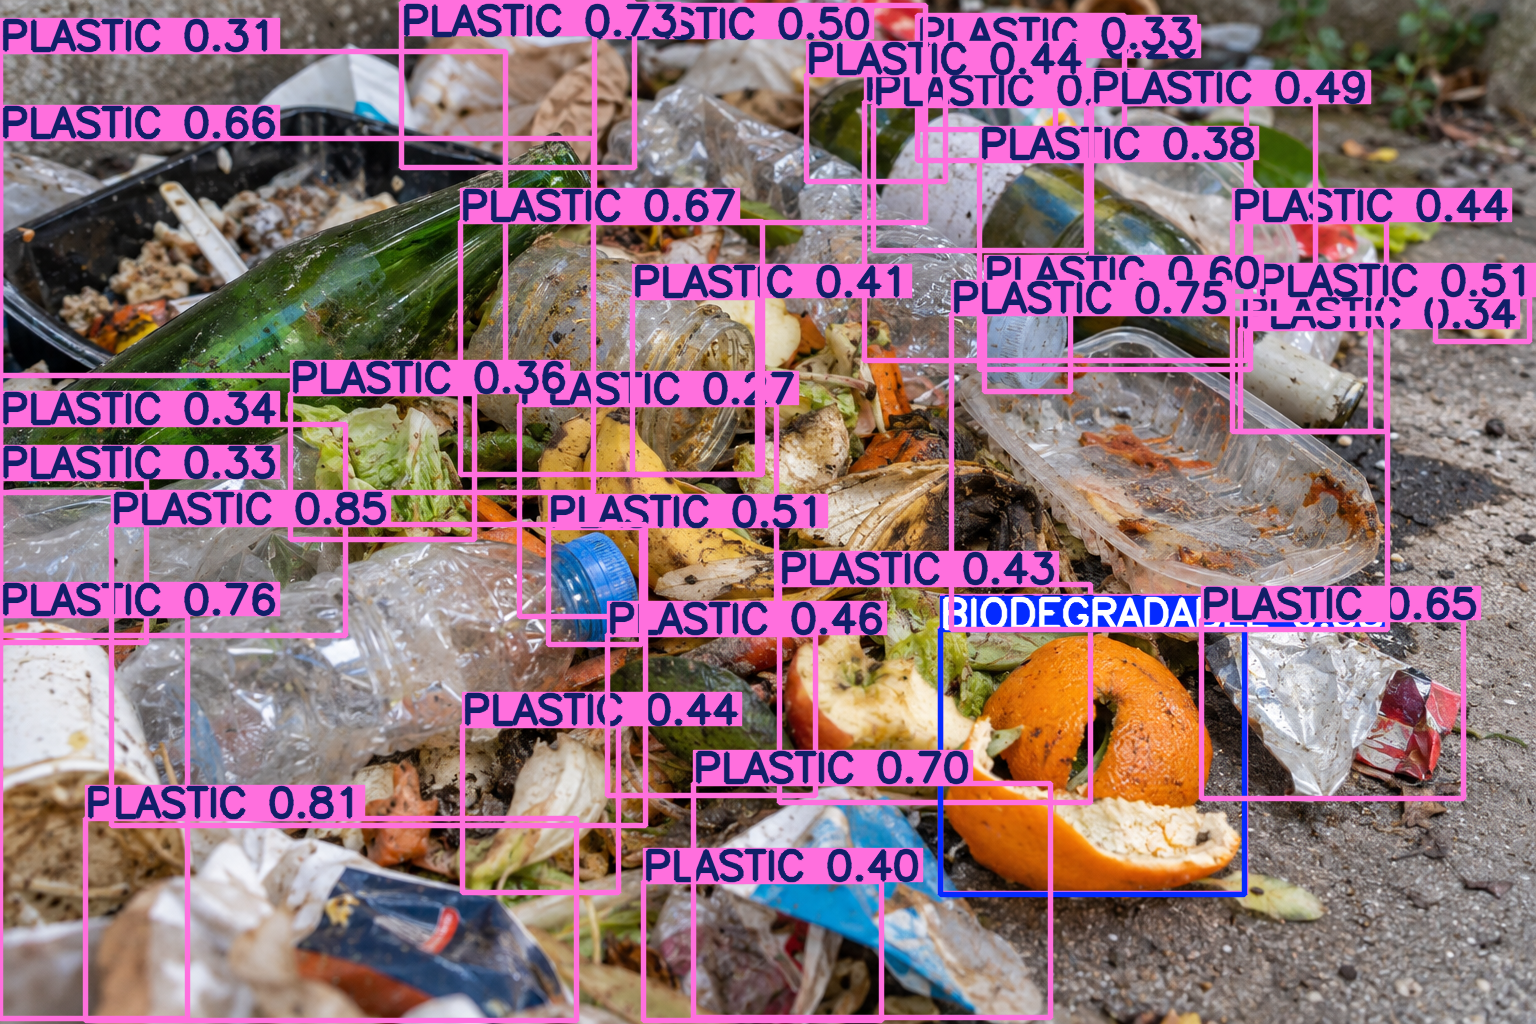

Total detected waste: 34
Organic objects: 1
Organic share: 2.9%
Organic waste does not exceed 30% of detected waste.


In [ ]:
from google.colab import files
from ultralytics import YOLO
from PIL import Image, ImageOps
from IPython.display import display
from io import BytesIO
from pathlib import Path
import torch

# best result file
MODEL_PATH = Path(
    "/content/drive/MyDrive/waste_to_value/"
    "yolo26m_resplit_seed42-2/weights/best.pt"
)

assert MODEL_PATH.exists(), f"Model not found: {MODEL_PATH}"

upload_model = YOLO(str(MODEL_PATH))

# can be adjest
CONFIDENCE = 0.25

organic_ids = {
    int(cid)
    for cid, name in upload_model.names.items()
    if name.upper().replace(" ", "_")
    in {"BIODEGRADABLE", "ORGANIC", "ORGANIC_WASTE"}
}
assert organic_ids, "Organic class not found in model"

uploaded = files.upload()

for filename, image_bytes in uploaded.items():
    picture = ImageOps.exif_transpose(
        Image.open(BytesIO(image_bytes))
    ).convert("RGB")

    result = upload_model.predict(
        source=picture,
        imgsz=640,
        conf=CONFIDENCE,
        max_det=400,
        device=0 if torch.cuda.is_available() else "cpu",
        verbose=False
    )[0]


    annotated = Image.fromarray(result.plot()[:, :, ::-1])
    display(annotated)

    classes = result.boxes.cls.cpu().numpy().astype(int)
    total = len(classes)
    organic = sum(int(cid) in organic_ids for cid in classes)

    if total == 0:
        print("No waste detected. Organic share is unavailable.")
    else:
        percentage = organic / total * 100

        print(f"Total detected waste: {total}")
        print(f"Organic objects: {organic}")
        print(f"Organic share: {percentage:.1f}%")

        if organic / total > 0.30:
            print("⚠️ Organic waste exceeds 30% of detected waste.")
        else:
            print("Organic waste does not exceed 30% of detected waste.")

    #
    save_dir = MODEL_PATH.parent.parent / "uploaded_predictions"
    save_dir.mkdir(parents=True, exist_ok=True)
    annotated.save(save_dir / f"{Path(filename).stem}_detected.jpg")

In [ ]:
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

files = sorted(set(
    list(Path("/content/runs").rglob("results.csv")) +
    list(Path("/content/drive/MyDrive").rglob("results.csv"))
))

if not files:
    print("No results.csv found. The saved training log is needed.")
else:
    for i, file in enumerate(files):
        print(f"[{i}] {file}")

    if len(files) == 1:
        RUN_DIR = files[0].parent
        print("\nRUN_DIR =", RUN_DIR)
    else:
        print("\nSend me these paths so we can select the correct run.")

Mounted at /content/drive
[0] /content/drive/MyDrive/waste_to_value/yolo26m_A/results.csv
[1] /content/drive/MyDrive/waste_to_value/yolo26m_resplit_seed42/results.csv
[2] /content/drive/MyDrive/waste_to_value/yolo26m_resplit_seed42-2/results.csv

Send me these paths so we can select the correct run.


In [ ]:
selected = 2  # changed to the file number

RESULTS_CSV = files[selected]
RUN_DIR = RESULTS_CSV.parent

print("Selected:", RESULTS_CSV)

Selected: /content/drive/MyDrive/waste_to_value/yolo26m_resplit_seed42-2/results.csv


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


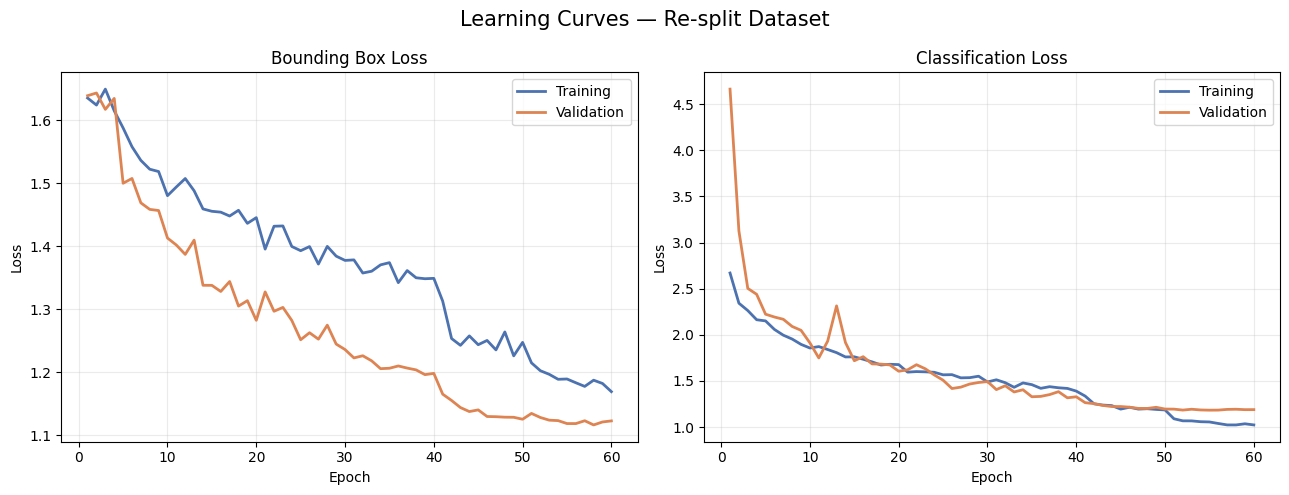

Training log: /content/drive/MyDrive/waste_to_value/yolo26m_resplit_seed42-2/results.csv
Last recorded epoch: 60
Figure saved to: /content/learning_curves.png


In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount("/content/drive")

# Saved training results — 60-epoch run
RESULTS_CSV = Path(
    "/content/drive/MyDrive/waste_to_value/"
    "yolo26m_resplit_seed42-2/results.csv"
)

if not RESULTS_CSV.is_file():
    raise FileNotFoundError(f"Training log not found: {RESULTS_CSV}")

history = pd.read_csv(RESULTS_CSV)
history.columns = history.columns.str.strip()

required = [
    "epoch",
    "train/box_loss", "val/box_loss",
    "train/cls_loss", "val/cls_loss"
]

missing = [column for column in required if column not in history.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, loss, title in zip(
    axes,
    ["box", "cls"],
    ["Bounding Box Loss", "Classification Loss"]
):
    ax.plot(
        history["epoch"],
        history[f"train/{loss}_loss"],
        label="Training",
        color="#4C72B0",
        linewidth=2
    )
    ax.plot(
        history["epoch"],
        history[f"val/{loss}_loss"],
        label="Validation",
        color="#DD8452",
        linewidth=2
    )

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.grid(alpha=0.25)
    ax.legend()

fig.suptitle("Learning Curves — Re-split Dataset", fontsize=15)
plt.tight_layout()

# Save a high-resolution copy for the presentation
plt.savefig("/content/learning_curves.png", dpi=300, bbox_inches="tight")
plt.show()

print("Training log:", RESULTS_CSV)
print("Last recorded epoch:", history["epoch"].max())
print("Figure saved to: /content/learning_curves.png")